# Z-score mean reversion

Buy SPY when its rolling Z-score falls below `-entry`. Exit when it reaches zero.
Compare with buy-and-hold SPY using cached five-minute bars, including extended hours.
Signals use closed bars and earn the next bar's return. Cash earns zero; reported backtests exclude costs and dividends.

In [ ]:
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from common.backtest import backtest
from common.market_data import ParquetMarketView
from common.strategies.buy_and_hold import BuyAndHoldStrategy
from common.strategies.zscore import ZScoreStrategy

In [ ]:
directory = "./data" if Path("./data").is_dir() else "../data"

start = datetime(2023, 1, 1, tzinfo=timezone.utc)
split = datetime(2024, 1, 1, tzinfo=timezone.utc)
end = datetime(2025, 1, 1, tzinfo=timezone.utc)

view = ParquetMarketView(directory, minutes=5)

## Experiment: window and entry threshold

Choose the highest 2023 Sharpe, then test that choice on 2024. Windows count bars.
Sharpe uses the backtest engine's annualization and a zero risk-free rate.

In [2]:
scores = []
for window in [20, 50, 100]:
    for entry in [1.5, 2.0, 2.5]:
        report = backtest(ZScoreStrategy(["SPY"], window, entry), view, start, split, progress=False)
        scores.append((report.sharpe, window, entry))
        print(f"window={window:3}, entry={entry}: profit {report.profit:7.2%}, sharpe {report.sharpe:.2f}")

_, window, entry = max(scores)
print(f"Selected: window={window}, entry={entry}")

window= 20, entry=1.5: profit  15.50%, sharpe 1.81
window= 20, entry=2.0: profit  12.42%, sharpe 1.62
window= 20, entry=2.5: profit  -0.84%, sharpe -0.12
window= 50, entry=1.5: profit   5.96%, sharpe 0.77
window= 50, entry=2.0: profit   7.97%, sharpe 1.06
window= 50, entry=2.5: profit   5.12%, sharpe 0.79
window=100, entry=1.5: profit  15.31%, sharpe 1.80
window=100, entry=2.0: profit  13.58%, sharpe 1.70
window=100, entry=2.5: profit  12.28%, sharpe 1.68
Selected: window=20, entry=1.5


## Backtest: 2024 vs SPY

Both runs start flat and use the same prices and dates. Equity starts at $1.

In [3]:
zscore = backtest(ZScoreStrategy(["SPY"], window, entry), view, split, end, progress=False)
baseline = backtest(BuyAndHoldStrategy(["SPY"]), view, split, end, progress=False)

for name, report in [("Z-score SPY", zscore), ("Buy & hold SPY", baseline)]:
    drawdown = (1 - report.equity / report.equity.cummax()).max()
    print(f"{name}: profit {report.profit:.2%}, sharpe {report.sharpe:.2f}, max drawdown {drawdown:.2%}")

Z-score SPY: profit 5.32%, sharpe 0.70, max drawdown 6.51%
Buy & hold SPY: profit 23.45%, sharpe 1.75, max drawdown 9.97%


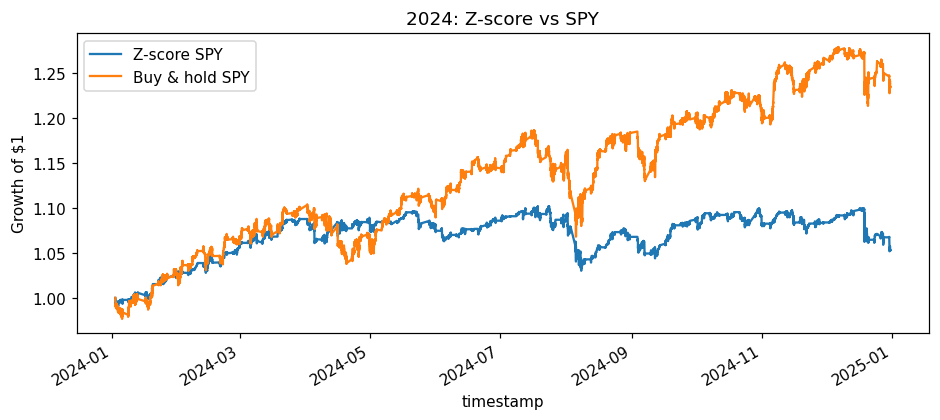

In [4]:
equity = pd.DataFrame({"Z-score SPY": zscore.equity, "Buy & hold SPY": baseline.equity})
equity.plot(figsize=(10, 4), title="2024: Z-score vs SPY", ylabel="Growth of $1")
plt.show()

## Experiment: trading costs

Subtract 0, 1 and 5 bps per unit of one-way turnover, when the next position starts earning returns.
Positions remain open at the end. This still assumes fills at the signal close.

In [5]:
for name, report in [("Z-score SPY", zscore), ("Buy & hold SPY", baseline)]:
    held = report.weights.shift(1).fillna(0.0)
    turnover = held.diff().fillna(held).abs().sum(axis=1)
    for bps in [0, 1, 5]:
        returns = report.returns - turnover * bps / 10_000
        profit = (1 + returns).prod() - 1
        print(f"{name}, cost={bps} bps: profit {profit:.2%}")

Z-score SPY, cost=0 bps: profit 5.32%
Z-score SPY, cost=1 bps: profit -16.85%
Z-score SPY, cost=5 bps: profit -67.71%
Buy & hold SPY, cost=0 bps: profit 23.45%
Buy & hold SPY, cost=1 bps: profit 23.43%
Buy & hold SPY, cost=5 bps: profit 23.39%


The selected rule trails SPY in 2024: 5.32% vs 23.45% before costs.
At 1 bp per side, its return falls to -16.85%; frequent trading consumes the gross gain.
The parameter search is in-sample. One held-out year and close-price fills do not establish a reliable edge.